# Conclusiones

*Redacción final del capítulo de conclusiones. Las cifras y las figuras se calculan en este mismo notebook, salvo la escalera de la sección 2, que se estima en `interpretation.ipynb` y aquí solo se grafica. Las figuras se guardan en `figures/conclusion-*.svg`.*

In [1]:
from nbsetup import *
import statsmodels.formula.api as smf
from pipeline import Datos, muestra_comun, Panel, tabla_resultados, NIVELES_TESIS

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

datos = Datos()
emparejamientos, comunes = muestra_comun(datos)
RADIO = 300
e300 = emparejamientos[RADIO]
boot = pd.read_parquet(DATA / "bootstrap-coeficientes.parquet")

# misma paleta que las figuras del capítulo 3 (propensity-score.ipynb)
TRATADA, CONTROL, TINTA, GRIS = "#BC4B51", "#7BA34A", "#2F4858", "#C4CACE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 9, "axes.linewidth": .6,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "svg.fonttype": "none",
})
FIGURAS = ROOT / "figures"


def limpiar(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRIS)
    ax.tick_params(colors=TINTA)
    return ax


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.svg", bbox_inches="tight")
    (FIGURAS / "png").mkdir(exist_ok=True)
    fig.savefig(FIGURAS / "png" / f"{nombre}.png", bbox_inches="tight", dpi=300)


NOMBRE_NIVEL = {"general": "Todos los incidentes", "MIN": "Sin lesionados (MIN)",
                "PIC": "Con lesionados (PIC)", "FCS": "Fatales (FCS)"}

## 1. Sobre qué unidades se puede concluir

Lo que estimo es el efecto promedio sobre las unidades tratadas (ATT), pero no sobre todas. De las 99 unidades que forman las 113 cámaras, 93 encuentran un control comparable dentro del caliper en los cinco radios. Una no lo encuentra a 300 m y las otras cinco fallan en algún otro radio. Las dejo fuera de todas las columnas para que los cinco radios describan exactamente las mismas zonas.

Las seis excluidas no son un descarte al azar. Son las zonas más peligrosas de la red: antes de las Fotocívicas registraban 13.5 incidentes al mes, 2.2 veces lo de las 93 que sí analizo. Las seis habían tenido al menos un incidente fatal (contra 70% de las demás), tienen más carriles y más vía de acceso controlado, triplican la afluencia de metro y su siniestralidad venía creciendo más rápido. No se parecen a ningún lugar sin cámara de la ciudad, y por eso el emparejamiento no les encuentra pareja.

La figura compara a las seis excluidas y a los 93 controles emparejados contra las 93 tratadas que sí analizo. Cada punto es el valor del grupo dividido entre el de las 93, cuyo valor aparece entre paréntesis junto a cada variable.

La consecuencia es que mis conclusiones no se extienden a ellas. Si las cámaras funcionan mejor justo donde el riesgo es más alto, este análisis no lo puede ver.

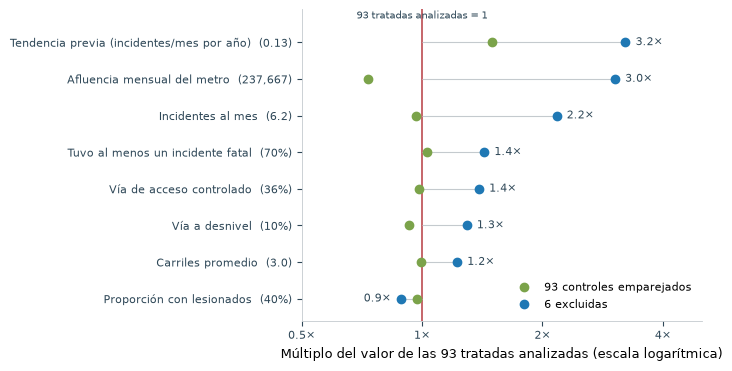

excluidas: T33, T50, T51, T60, T63, T90  |  {'tratadas sin control dentro del caliper': 1, 'fuera de la muestra común entre radios': 5}


In [2]:
m = e300.features.matriz
tratadas = m[m.tratado == 1]
excluidas = [u for u in tratadas.index if u not in set(comunes)]
COLUMNAS = {
    "nivel_incidentes": ("Incidentes al mes", "{:.1f}"),
    "tendencia": ("Tendencia previa (incidentes/mes por año)", "{:.2f}"),
    "afluencia_nivel": ("Afluencia mensual del metro", "{:,.0f}"),
    "pct_acceso_controlado": ("Vía de acceso controlado", "{:.0%}"),
    "hubo_fcs": ("Tuvo al menos un incidente fatal", "{:.0%}"),
    "pct_desnivel": ("Vía a desnivel", "{:.0%}"),
    "carriles_ponderados": ("Carriles promedio", "{:.1f}"),
    "pct_lesionados": ("Proporción con lesionados", "{:.0%}"),
}
perfil = pd.DataFrame({
    "excluidas": tratadas.loc[excluidas, list(COLUMNAS)].mean(),
    "analizadas": tratadas.loc[list(comunes), list(COLUMNAS)].mean(),
    "controles": m.loc[e300.pares.control, list(COLUMNAS)].mean(),
})
# cada grupo como múltiplo de las 93 tratadas analizadas: así caben en un solo eje
# variables que viven en escalas muy distintas
razon = perfil[["excluidas", "controles"]].div(perfil.analizadas, axis=0)
razon = razon.sort_values("excluidas")
EXCLUIDA = "#1F78B4"

fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
y = np.arange(len(razon))
ax.axvline(1, color=TRATADA, lw=1.2)
ax.text(1, len(razon) - .35, "93 tratadas analizadas = 1", color=TINTA, fontsize=7.5, ha="center")
ax.hlines(y, 1, razon.excluidas, color=GRIS, lw=.8)
ax.plot(razon.controles, y, "o", color=CONTROL, ms=6, label="93 controles emparejados")
ax.plot(razon.excluidas, y, "o", color=EXCLUIDA, ms=6, label="6 excluidas")
for yi, (variable, fila) in zip(y, razon.iterrows()):
    lado = "left" if fila.excluidas >= 1 else "right"
    ax.text(fila.excluidas * (1.06 if lado == "left" else 1 / 1.06), yi, f"{fila.excluidas:.1f}×",
            va="center", ha=lado, fontsize=8, color=TINTA)
etiquetas = [f"{COLUMNAS[v][0]}  ({COLUMNAS[v][1].format(perfil.loc[v, 'analizadas'])})"
             for v in razon.index]
ax.set_yticks(y, etiquetas)
ax.set_xscale("log")
ax.set_xticks([.5, 1, 2, 4], ["0.5×", "1×", "2×", "4×"])
ax.minorticks_off()
ax.set_xlim(.5, 5)
ax.set_ylim(-.6, len(razon) - .1)
ax.set_xlabel("Múltiplo del valor de las 93 tratadas analizadas (escala logarítmica)")
ax.legend(frameon=False, loc="lower right")
limpiar(ax)
guardar(fig, "conclusion-excluidas")
plt.show()

print(f"excluidas: {', '.join(excluidas)}  |  {e300.descartes}")


## 2. Cómo cambia el resultado conforme la comparación se vuelve más rigurosa

El efecto estimado depende mucho de contra qué se comparan las zonas con cámara. La figura sigue la misma pregunta a 300 m, con todos los incidentes, desde la comparación más ingenua hasta la especificación final.

**Antes y después, solo en las zonas tratadas.** Los incidentes bajan 0.94 al mes, 14% de su nivel previo. Leído así, el programa sería un éxito, pero esa caída incluye todo lo que le pasó a la ciudad después de abril de 2019, empezando por la pandemia.

**Tratadas contra controles, solo después.** Las zonas con cámara tienen 2.3 incidentes al mes más que el resto de la ciudad, 67% más. Nadie concluiría que las cámaras causan incidentes: el número dice que se instalaron en lugares que ya eran peligrosos.

**Diferencia en diferencias contra toda la ciudad.** Al comparar el cambio de las tratadas con el cambio de 631 zonas sin cámara se obtiene una reducción de 0.53 incidentes al mes, 13.7% de la media previa de los controles, con un p de 0.001. Es una cifra que cae dentro del rango que reporta la literatura internacional y que se obtiene con un contrafactual parecido al de Madrigal y Rodríguez (2021). Agregar efectos fijos de unidad y de tiempo no la mueve: en un panel balanceado con tratamiento simultáneo el coeficiente es idéntico por construcción.

**Solo las 93 unidades con soporte común.** Al quitar las seis zonas más peligrosas la reducción baja a 0.39 incidentes al mes (10.1%). Una cuarta parte del efecto anterior venía de esas seis.

**Emparejamiento.** Este es el paso que más pesa. Cuando cada zona tratada se compara con una zona sin cámara igual de peligrosa, la reducción cae a 0.15 incidentes al mes (2.5%) y deja de ser significativa. Los controles emparejados arrancan en 6.02 incidentes al mes, no en 3.84 como el resto de la ciudad, y en el periodo posterior bajan casi lo mismo que las tratadas. La mayor parte de la reducción que se veía en el paso anterior era la diferencia entre lugares peligrosos y lugares tranquilos, no el efecto de la cámara.

**Covariables × post.** Permitir que las zonas con distinta estructura vial y distinta afluencia de metro cambien de forma distinta después de 2019 deja el efecto en 0.11 incidentes al mes, 1.8% de la media previa del control.

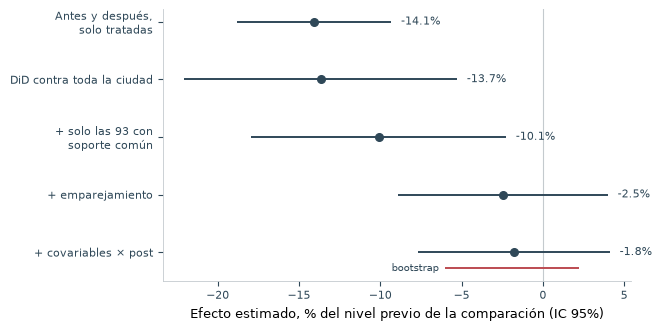

,comparación,tratadas,controles,coef,EE,base,%,IC bajo %,IC alto %
paso,,,,,,,,,
1,"Antes y después,\nsolo tratadas",99,0,-0.937,0.161,6.663,-14.069,-18.814,-9.324
2,"Tratadas contra controles,\nsolo después",99,631,2.296,0.310,3.430,66.951,49.217,84.685
3,DiD contra toda la ciudad,99,631,-0.525,0.165,3.842,-13.674,-22.072,-5.276
4,+ efectos fijos de\nunidad y tiempo,99,631,-0.525,0.166,3.842,-13.674,-22.138,-5.210
5,+ solo las 93 con\nsoporte común,93,631,-0.388,0.154,3.842,-10.110,-17.957,-2.263
6,+ emparejamiento,93,93,-0.148,0.198,6.019,-2.452,-8.902,3.998
7,+ covariables × post,93,93,-0.106,0.181,6.019,-1.766,-7.653,4.121


In [3]:
# Los siete pasos a 300 m con todos los incidentes. Se estiman en interpretation.ipynb
# (Parte I); aquí solo se grafican. El intervalo es el analítico agrupado por componente,
# salvo el paso 7, que además lleva el del bootstrap del proceso completo.
escalera = pd.DataFrame([
    (1, "Antes y después,\nsolo tratadas",           99,   0, -0.9374, 0.1613, 6.6630),
    (2, "Tratadas contra controles,\nsolo después",  99, 631,  2.2961, 0.3103, 3.4295),
    (3, "DiD contra toda la ciudad",                 99, 631, -0.5253, 0.1646, 3.8416),
    (4, "+ efectos fijos de\nunidad y tiempo",        99, 631, -0.5253, 0.1659, 3.8416),
    (5, "+ solo las 93 con\nsoporte común",           93, 631, -0.3884, 0.1538, 3.8416),
    (6, "+ emparejamiento",                          93,  93, -0.1476, 0.1981, 6.0194),
    (7, "+ covariables × post",                      93,  93, -0.1063, 0.1808, 6.0194),
], columns=["paso", "comparación", "tratadas", "controles", "coef", "EE", "base"]).set_index("paso")
escalera["%"] = 100 * escalera.coef / escalera.base
escalera["IC bajo %"] = 100 * (escalera.coef - 1.96 * escalera.EE) / escalera.base
escalera["IC alto %"] = 100 * (escalera.coef + 1.96 * escalera.EE) / escalera.base

b = boot.query("radio == @RADIO and nivel == 'general' and especificacion == '(3)'").coef
IC_BOOT = 100 * np.percentile(b, [2.5, 97.5]) / escalera.loc[7, "base"]

# el paso 2 (+67%) no es un DiD y aplastaría la escala; el 4 es idéntico al 3 por construcción
graficar = escalera.loc[[1, 3, 5, 6, 7]]
fig, ax = plt.subplots(figsize=(6.5, 3.2), layout="constrained")
y = np.arange(len(graficar))[::-1]
ax.axvline(0, color=GRIS, lw=.8)
ax.hlines(y, graficar["IC bajo %"], graficar["IC alto %"], color=TINTA, lw=1.4)
ax.plot(graficar["%"], y, "o", color=TINTA, ms=5.5)
ax.hlines(y[-1] - .28, *IC_BOOT, color=TRATADA, lw=1.4)
ax.text(IC_BOOT[0], y[-1] - .28, "bootstrap  ", ha="right", va="center", fontsize=7.5, color=TINTA)
for yi, (_, fila) in zip(y, graficar.iterrows()):
    ax.text(fila["IC alto %"] + .6, yi, f"{fila['%']:+.1f}%", va="center", fontsize=8, color=TINTA)
ax.set_yticks(y, graficar.comparación)
ax.set_xlabel("Efecto estimado, % del nivel previo de la comparación (IC 95%)")
limpiar(ax)
guardar(fig, "conclusion-escalera")
plt.show()

escalera.round(3)

En la especificación final, el intervalo de confianza del bootstrap del proceso completo va de una reducción de 6.0% a un aumento de 2.2% de la media previa del control. Los datos son compatibles con que las cámaras no hayan tenido efecto y también con una reducción moderada, pero no con una grande.

Que no puedan descartarse reducciones de hasta 6% importa. Si hubiera estimado una reducción de ese tamaño la habría considerado plausible: la literatura internacional reporta reducciones de entre 12% y 28% en incidentes con lesionados (Li et al., 2013, 2020; Graham et al., 2019; Mountain et al., 2005), pero sobre el tramo de vía inmediato a la cámara, mientras que yo mido un área circular en la que el efecto se diluye. Bajo el supuesto de tendencias paralelas, lo que el intervalo sí descarta son reducciones del tamaño de esa literatura y de la hipótesis con la que empecé, del orden de 10% a 20%. Ese supuesto no se rechaza en los datos previos (sección 6), pero tampoco se puede confirmar con precisión.

El ancho del intervalo también marca el límite del diseño. Para que un efecto se hubiera distinguido de cero tendría que haber sido grande: más de 6% en el total de incidentes, más de 9% en los incidentes con lesionados y, en los fatales, de varias decenas de por ciento.

## 3. Por tipo de incidente

Separar los incidentes por severidad no cambia la conclusión. En la especificación final, todos los intervalos de los cinco radios y los cuatro tipos de incidente incluyen el cero.

- **Todos los incidentes.** El estimado puntual es positivo a 100 m y negativo en los demás radios, sin un patrón claro: ninguna reducción puntual supera el 2.6%, que es la de 250 m.
- **Sin lesionados (MIN).** La mayor reducción puntual es de 4.0% a 150 m, y a partir de ahí se diluye. El valor positivo a 100 m parece más ruido que efecto.
- **Con lesionados (PIC).** Es el único tipo en el que el estimado puntual baja conforme crece el radio, de +9.5% a 100 m a −4.3% a 250 m, para volver a −2.8% a 300 m. Pero a 100 y 150 m es positivo y todos los intervalos cruzan el cero, así que el patrón no es distinguible del azar.
- **Fatales (FCS).** Hay 411 incidentes fatales en el panel a 300 m, el 0.5% del total. Los intervalos van de reducciones de 17% a 42% hasta aumentos de 37% a 56%, según el radio. Estas estimaciones no permiten concluir nada sobre las muertes, ni a favor ni en contra, y se reportan solo por completitud.

In [4]:
resultados = tabla_resultados(emparejamientos)
resultados["espec"] = resultados.especificacion.str[:3]
ic = (boot.groupby(["radio", "nivel", "especificacion"]).coef
      .quantile([.025, .975]).unstack().set_axis(["ic_bajo", "ic_alto"], axis=1)
      .reset_index().rename(columns={"especificacion": "espec"}))
resultados = resultados.merge(ic, on=["radio", "nivel", "espec"], how="left")
for c in ("ic_bajo", "ic_alto"):
    resultados[f"{c} %"] = 100 * resultados[c] / resultados.media_control

principal = resultados.query("espec == '(3)'")
(principal.pivot_table(index="nivel", columns="radio",
                       values=["% del control", "ic_bajo %", "ic_alto %"])
 .reindex(list(NOMBRE_NIVEL)).round(1))

% del control                        ic_alto %                         ic_bajo %                        
radio             100  150   200   250   300       100   150   200   250   300       100   150   200   250   300
nivel                                                                                                           
general           5.6 -1.4  -2.4  -2.6  -1.8       8.0   4.8   4.5   3.1   2.2      -5.7  -6.7  -6.0  -5.6  -6.0
MIN               3.1 -4.0  -2.9  -1.7  -1.2       6.8   3.6   3.7   3.7   3.0      -8.8  -9.8  -6.8  -5.3  -5.9
PIC               9.5  2.3  -1.3  -4.3  -2.8      13.4   9.6   8.6   4.6   3.4      -4.5  -5.7  -7.6  -8.6  -9.2
FCS              -7.7  3.4 -17.4  18.6  11.6      51.3  51.0  55.9  36.7  37.1     -42.1 -33.3 -42.3 -19.4 -17.4

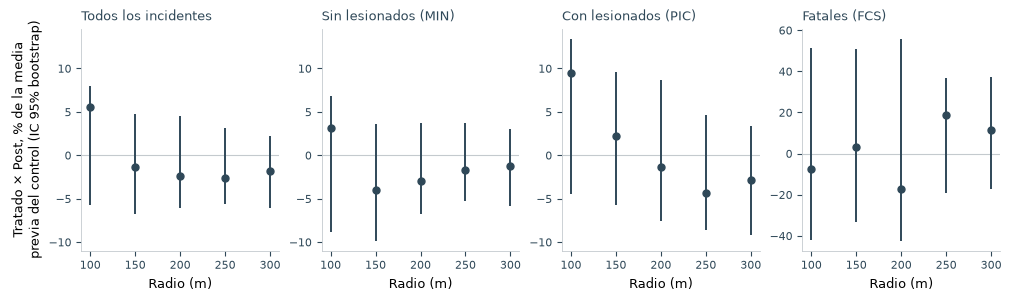

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(10, 2.9), sharex=True, layout="constrained")
for ax in axes[1:3]:
    ax.sharey(axes[0])   # FCS va en su propia escala: sus intervalos son diez veces más anchos
for ax, nivel in zip(axes, NOMBRE_NIVEL):
    d = principal.query("nivel == @nivel").sort_values("radio")
    ax.axhline(0, color=GRIS, lw=.8)
    ax.vlines(d.radio, d["ic_bajo %"], d["ic_alto %"], color=TINTA, lw=1.4)
    ax.plot(d.radio, d["% del control"], "o", color=TINTA, ms=5)
    ax.set_title(NOMBRE_NIVEL[nivel], fontsize=9, loc="left", color=TINTA)
    ax.set_xticks(d.radio, [f"{r}" for r in d.radio])
    ax.set_xlabel("Radio (m)")
    limpiar(ax)
axes[0].set_ylabel("Tratado × Post, % de la media\nprevia del control (IC 95% bootstrap)")
guardar(fig, "conclusion-por-nivel")
plt.show()

## 4. La brecha entre tratadas y controles

El modelo sin efectos fijos tiene cuatro coeficientes que se leen directamente como medias. El intercepto es el nivel de los controles antes del tratamiento; `tratado`, cuánto más tenían las tratadas en ese mismo periodo; `post`, cuánto cambiaron los controles; y `tratado × post`, cuánto cambiaron las tratadas *además* de lo que cambiaron los controles, que es el efecto. La suma `tratado + tratado × post` es la brecha que queda entre tratadas y controles después del tratamiento.

A 300 m, antes del tratamiento las tratadas tenían 0.20 incidentes al mes más que sus controles (6.22 contra 6.02), y después 0.06 (5.42 contra 5.37). Es tentador leer que las cámaras acercaron a las zonas tratadas al nivel de sus controles, pero ese cierre de 0.15 es exactamente el coeficiente DiD contado de otra forma, no una evidencia adicional, y no es distinguible de cero. Tampoco se repite en los demás radios: a 100 m la brecha se abre, y entre 150 y 250 m cambia de signo.

Lo que sí permite decir es descriptivo. El emparejamiento dejó a las tratadas en el mismo nivel que sus controles antes del tratamiento, y después del tratamiento la brecha sigue sin ser distinguible de cero en ningún radio. Las zonas con cámara no quedaron ni más ni menos peligrosas que zonas comparables sin cámara.

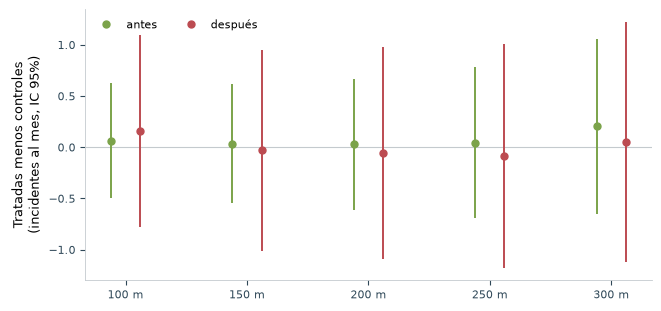

,tratado,EE_tratado,suma,EE_suma,coef
radio,,,,,
100,0.063,0.287,0.158,0.477,0.094
150,0.035,0.295,-0.029,0.501,-0.064
200,0.027,0.326,-0.055,0.526,-0.083
250,0.046,0.374,-0.083,0.558,-0.129
300,0.203,0.435,0.055,0.597,-0.148


In [6]:
# modelo (1): `tratado` es la brecha antes; `tratado + tratado:post`, la brecha después
uno = resultados.query("espec == '(1)' and nivel == 'general'").sort_values("radio")
fig, ax = plt.subplots(figsize=(6.5, 3), layout="constrained")
ax.axhline(0, color=GRIS, lw=.8)
for desplazamiento, columna, ee, color, etiqueta in [
        (-6, "tratado", "EE_tratado", CONTROL, "antes"),
        (6, "suma", "EE_suma", TRATADA, "después")]:
    x = uno.radio + desplazamiento
    ax.vlines(x, uno[columna] - 1.96 * uno[ee], uno[columna] + 1.96 * uno[ee], color=color, lw=1.4)
    ax.plot(x, uno[columna], "o", color=color, ms=5, label=etiqueta)
ax.set_xticks(uno.radio, [f"{r} m" for r in uno.radio])
ax.set_ylabel("Tratadas menos controles\n(incidentes al mes, IC 95%)")
ax.legend(frameon=False, loc="upper left", ncols=2)
limpiar(ax)
guardar(fig, "conclusion-brecha")
plt.show()

uno.set_index("radio")[["tratado", "EE_tratado", "suma", "EE_suma", "coef"]].round(3)

## 5. La pandemia

El periodo posterior incluye los dos primeros años de la pandemia de COVID-19, y en los datos se nota. Entre marzo y mayo de 2020 los incidentes por unidad cayeron de alrededor de 6 al mes a 2.5, una caída cercana a 57%, y no recuperaron su nivel previo hasta finales de 2021. El volumen vehicular en las casetas de peaje cayó 46% en abril de 2020, en línea con la reducción de alrededor de 45% en la afluencia vehicular que reporta la Secretaría de Movilidad para la ciudad.

Lo que hace manejable la pandemia es que golpeó por igual a los dos grupos: las series de tratadas y controles caen y se recuperan juntas. Los efectos fijos de tiempo absorben cualquier choque que afecte a todas las unidades en el mismo mes, así que la caída de 2020 no se confunde con el efecto de las cámaras. Por eso dejé el volumen de las casetas fuera del modelo. Es una sola serie para toda la ciudad, el mismo número para todas las unidades en cada mes, y los efectos fijos de tiempo ya contienen toda su información. Usarla como denominador de una tasa tampoco controla nada, porque divide a todas las unidades del mes entre el mismo número: solo cambia el peso relativo de cada mes y complica la interpretación del coeficiente.

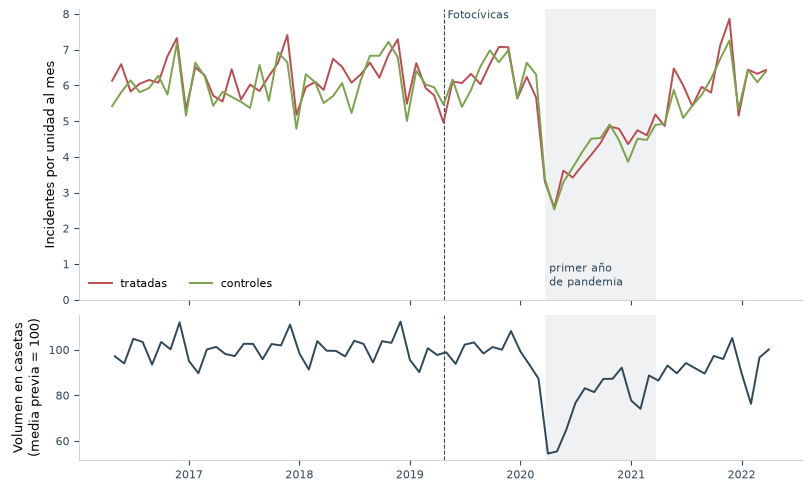

volumen en casetas: mínimo de 54 en April 2020


/var/folders/5y/svz9vhw14gvb8jpp9pz8sm800000gn/T/ipykernel_56959/2141353655.py:29: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  serie.loc[[-1, 11, 12, 35], ["inicio", "tratadas", "controles"]].round(2)


,inicio,tratadas,controles
t,,,
-1,2019-03-22,5.72,5.95
11,2020-03-22,3.30,3.39
12,2020-04-22,2.58,2.53
35,2022-03-22,6.43,6.39


In [7]:
panel = Panel(e300)
serie = (panel.tabla.groupby(["t", "tratado"]).incidentes.mean().unstack()
         .rename(columns={0: "controles", 1: "tratadas"})
         .join(panel.periodos.set_index("t").inicio))
volumen = datos.volumen.set_index("timestamp").volumen_mensual
indice = 100 * volumen / volumen[volumen.index < datos.fecha_tratamiento].mean()
PANDEMIA = pd.Timestamp("2020-03-23")   # Jornada Nacional de Sana Distancia

fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True,
                                    height_ratios=[2, 1], layout="constrained")
for ax in (arriba, abajo):
    ax.axvline(datos.fecha_tratamiento, color=TINTA, lw=.8, ls="--")
    ax.axvspan(PANDEMIA, PANDEMIA + pd.DateOffset(years=1), color=GRIS, alpha=.25, lw=0)
    limpiar(ax)
for columna, color in [("tratadas", TRATADA), ("controles", CONTROL)]:
    arriba.plot(serie.inicio, serie[columna], color=color, lw=1.4, label=columna)
arriba.legend(frameon=False, loc="lower left", ncols=2)
arriba.set_ylim(bottom=0)
arriba.set_ylabel("Incidentes por unidad al mes")
arriba.text(datos.fecha_tratamiento, arriba.get_ylim()[1], " Fotocívicas", fontsize=8,
            color=TINTA, va="top")
arriba.text(PANDEMIA, 0.4, " primer año\n de pandemia", fontsize=8, color=TINTA)
abajo.plot(indice.index, indice, color=TINTA, lw=1.4)
abajo.set_ylabel("Volumen en casetas\n(media previa = 100)")
guardar(fig, "conclusion-pandemia")
plt.show()

print(f"volumen en casetas: mínimo de {indice.min():.0f} en {indice.idxmin():%B %Y}")
serie.loc[[-1, 11, 12, 35], ["inicio", "tratadas", "controles"]].round(2)

Para revisar si el año de la pandemia carga el resultado estimé un coeficiente distinto para cada año posterior:

```text
(3)        incidentes ~ tratado:post + [8 covariables]:post + C(uid) + C(t)
por año    incidentes ~ tratado:año1 + tratado:año2 + tratado:año3
                        + [8 covariables]:año1 + [8 covariables]:año2 + [8 covariables]:año3
                        + C(uid) + C(t)
```

Es la especificación (3) con `post` separado en tres indicadores anuales, y con errores estándar agrupados por componente traslapada. Los coeficientes de interés son `tratado:año1`, `tratado:año2` y `tratado:año3`: el efecto en cada año, medido contra los 36 meses previos. Los años van del 22 de abril al 21 de abril. El primero, de 2019 a 2020, cierra con el primer mes del confinamiento; el segundo, de 2020 a 2021, es el año de la pandemia, y el tercero va de 2021 a 2022.

A 300 m, con todos los incidentes, la reducción estimada es de 4.4% el primer año, 1.2% el segundo, que es el año de la pandemia, y prácticamente cero el tercero. Ningún año se distingue de cero, y no se puede rechazar que los tres sean iguales (p = 0.51). El año de la pandemia no se aparta de los demás. El patrón decreciente de los estimados puntuales coincide con lo que encuentran Li et al. (2020), efectos que se atenúan con el tiempo, pero con estos intervalos no se puede distinguir del azar. Los incidentes con lesionados siguen el mismo patrón (−7.0%, −3.3% y +1.8%, p = 0.32).

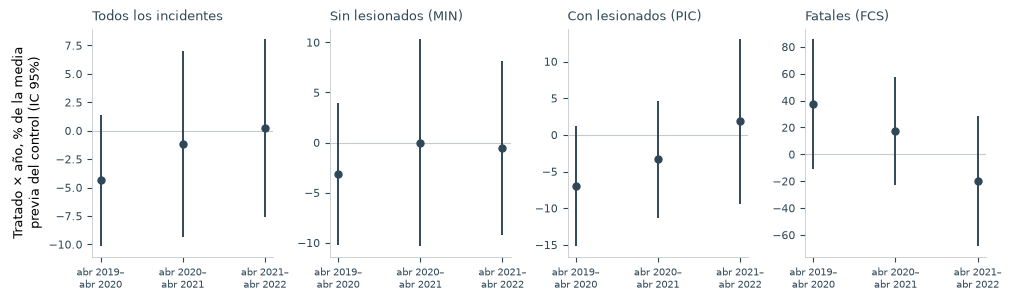

año   coef     EE       %  IC bajo %  IC alto %  p igualdad entre años
nivel                                                                              
general 0  año 1 -0.263  0.178  -4.377    -10.173      1.418                  0.512
        1  año 2 -0.071  0.252  -1.172     -9.366      7.022                  0.512
        2  año 3  0.015  0.240   0.251     -7.560      8.061                  0.512
MIN     0  año 1 -0.115  0.133  -3.127    -10.178      3.924                  0.787
        1  año 2 -0.000  0.194  -0.012    -10.358     10.334                  0.787
        2  año 3 -0.020  0.163  -0.536     -9.188      8.117                  0.787
PIC     0  año 1 -0.162  0.096  -7.027    -15.208      1.153                  0.315
        1  año 2 -0.076  0.094  -3.318    -11.311      4.674                  0.315
        2  año 3  0.042  0.132   1.825     -9.417     13.067                  0.315
FCS     0  año 1  0.013  0.009  37.526    -10.789     85.842                  0.133
        1  año 2  0.006  0.007  17.470    -22.553     57.493                  0.133
        2  año 3 -0.007  0.009 -20.145    -68.499     28.208                  0.133

In [8]:
ANIOS = {"año 1": (0, 11), "año 2": (12, 23), "año 3": (24, 35)}


def efecto_por_anio(emparejamiento, niveles=None):
    """El DiD de la especificación (3), con un coeficiente por año posterior."""
    p = Panel(emparejamiento, niveles=niveles)
    tabla = p.tabla.copy()
    for k, (desde, hasta) in enumerate(ANIOS.values(), start=1):
        anio = tabla.t.between(desde, hasta).astype(int)
        tabla[f"trat_a{k}"] = tabla.tratado * anio
        for c in p.covariables:
            tabla[f"{c}_a{k}"] = tabla[f"z_{c}"] * anio
    formula = ("incidentes ~ trat_a1 + trat_a2 + trat_a3 + "
               + " + ".join(f"{c}_a{k}" for k in (1, 2, 3) for c in p.covariables)
               + " + C(uid) + C(t)")
    r = smf.ols(formula, data=tabla).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(tabla.cluster)[0]})
    base = tabla[(tabla.tratado == 0) & (tabla.t < 0)].incidentes.mean()
    igualdad = float(r.wald_test("trat_a1 = trat_a2, trat_a2 = trat_a3", scalar=True).pvalue)
    return pd.DataFrame([{
        "año": anio, "coef": r.params[f"trat_a{k}"], "EE": r.bse[f"trat_a{k}"],
        "%": 100 * r.params[f"trat_a{k}"] / base,
        "IC bajo %": 100 * (r.params[f"trat_a{k}"] - 1.96 * r.bse[f"trat_a{k}"]) / base,
        "IC alto %": 100 * (r.params[f"trat_a{k}"] + 1.96 * r.bse[f"trat_a{k}"]) / base,
        "p igualdad entre años": igualdad,
    } for k, anio in enumerate(ANIOS, start=1)])


por_anio = pd.concat({nivel: efecto_por_anio(e300, niveles)
                      for nivel, niveles in NIVELES_TESIS.items()}, names=["nivel"])

fig, axes = plt.subplots(1, 4, figsize=(10, 2.9), sharex=True, layout="constrained")
for ax, nivel in zip(axes, NOMBRE_NIVEL):
    d = por_anio.loc[nivel]
    x = np.arange(len(d))
    ax.axhline(0, color=GRIS, lw=.8)
    ax.vlines(x, d["IC bajo %"], d["IC alto %"], color=TINTA, lw=1.4)
    ax.plot(x, d["%"], "o", color=TINTA, ms=5)
    ax.set_xticks(x, ["abr 2019–\nabr 2020", "abr 2020–\nabr 2021", "abr 2021–\nabr 2022"],
                  fontsize=7)
    ax.set_title(NOMBRE_NIVEL[nivel], fontsize=9, loc="left", color=TINTA)
    limpiar(ax)
axes[0].set_ylabel("Tratado × año, % de la media\nprevia del control (IC 95%)")
guardar(fig, "conclusion-por-anio")
plt.show()

por_anio.round(3)

Queda una forma en la que la pandemia sí podría sesgar el resultado: si cambió el tránsito de forma distinta en las zonas tratadas. La Secretaría de Movilidad documenta que, con menos autos, las velocidades subieron y los incidentes graves se concentraron en vías primarias y de acceso controlado, que es donde están las cámaras. El emparejamiento iguala la proporción de vía de acceso controlado entre tratadas y controles, y las covariables × post dejan que esas zonas cambien distinto después de 2019, lo que cubre la parte del choque que depende de la estructura vial. Lo que no cubre es lo que pasó con el tránsito dentro de cada zona, porque no tengo datos de aforo vehicular ni de velocidad de circulación dentro de la ciudad. Con ellos se podría medir la exposición de cada unidad mes a mes, y sería la mejora más valiosa para este análisis.

## 6. Las tendencias previas

El supuesto que sostiene la diferencia en diferencias es que, sin cámaras, tratadas y controles habrían seguido trayectorias paralelas. No se puede verificar después del tratamiento, pero sí se puede revisar si venían en paralelo antes.

Para revisarlo estimo un *event study*: la misma especificación de la sección 5, pero con un coeficiente para cada año, antes y después del tratamiento, y el año previo a las Fotocívicas como referencia.

```text
incidentes ~ tratado:año-3 + tratado:año-2 + tratado:año1 + tratado:año2 + tratado:año3
             + [8 covariables]:año-3 + ... + [8 covariables]:año3
             + C(uid) + C(t)
```

Cada coeficiente mide cuánto se separaron las tratadas de sus controles en ese año, comparado con el año −1 (abril de 2018 a abril de 2019). Si las tendencias eran paralelas, los coeficientes de los años −3 y −2 deberían estar cerca de cero.

Lo están en los cinco radios. Ninguno se distingue de cero, ninguno pasa de 4% de la media previa del control, y la prueba conjunta de que ambos son cero no se rechaza en ningún radio (p entre 0.54 y 0.99). A 300 m los dos coeficientes previos son positivos y van bajando hacia la referencia (+2.2% y +1.1%): las tratadas venían creciendo un poco menos que sus controles, aunque la diferencia es muy chica para distinguirla del azar. Después del tratamiento tampoco aparece un quiebre. El primer año es el más negativo en cuatro de los cinco radios, pero su intervalo incluye el cero en todos, y para el tercer año los estimados regresan a cero o se vuelven positivos en cuatro de los cinco radios.

El event study no encuentra evidencia en contra de las tendencias paralelas. Eso no prueba que se cumplan: con intervalos de entre ±6% y ±8% por año, una diferencia de tendencias del tamaño del efecto estimado pasaría desapercibida. Por eso aparece entre las limitaciones.

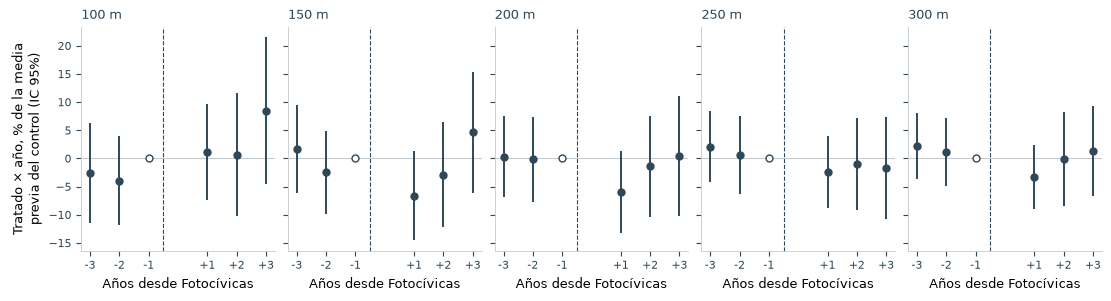

coef     EE  coef %   EE %  p previos = 0
radio año                                            
100   -3  -0.057  0.101  -2.563  4.542          0.617
      -2  -0.088  0.090  -3.946  4.043          0.617
      -1   0.000  0.000   0.000  0.000          0.617
       1   0.026  0.097   1.172  4.356          0.617
       2   0.014  0.124   0.637  5.572          0.617
       3   0.189  0.147   8.493  6.633          0.617
150   -3   0.050  0.118   1.683  3.995          0.541
      -2  -0.074  0.110  -2.503  3.740          0.541
      -1   0.000  0.000   0.000  0.000          0.541
       1  -0.197  0.119  -6.667  4.034          0.541
       2  -0.084  0.140  -2.865  4.745          0.541
       3   0.136  0.163   4.598  5.519          0.541
200   -3   0.011  0.142   0.291  3.666          0.989
      -2  -0.008  0.149  -0.199  3.842          0.989
      -1   0.000  0.000   0.000  0.000          0.989
       1  -0.232  0.143  -6.006  3.706          0.989
       2  -0.053  0.177  -1.373  4.578          0.989
       3   0.015  0.209   0.396  5.419          0.989
250   -3   0.102  0.162   2.026  3.216          0.802
      -2   0.030  0.178   0.598  3.534          0.802
      -1   0.000  0.000   0.000  0.000          0.802
       1  -0.119  0.163  -2.375  3.242          0.802
       2  -0.054  0.210  -1.074  4.173          0.802
       3  -0.088  0.232  -1.749  4.606          0.802
300   -3   0.132  0.180   2.188  2.994          0.765
      -2   0.064  0.186   1.070  3.093          0.765
      -1   0.000  0.000   0.000  0.000          0.765
       1  -0.198  0.176  -3.291  2.931          0.765
       2  -0.005  0.255  -0.086  4.234          0.765
       3   0.080  0.247   1.337  4.097          0.765

In [9]:
# Event study por años: los años -3 y -2 contra el año -1, que es la referencia,
# más los tres años posteriores. Las covariables se interactúan con cada año, como en
# la sección 5, para que la especificación sea la (3) separada por año.
EVENTO = {-3: (-36, -25), -2: (-24, -13), 1: (0, 11), 2: (12, 23), 3: (24, 35)}


def event_study(emparejamiento, niveles=None):
    p = Panel(emparejamiento, niveles=niveles)
    tabla = p.tabla.copy()
    terminos, nombres = [], {}
    for k, (desde, hasta) in EVENTO.items():
        sufijo = f"m{-k}" if k < 0 else f"p{k}"
        anio = tabla.t.between(desde, hasta).astype(int)
        tabla[f"trat_{sufijo}"] = tabla.tratado * anio
        nombres[k] = f"trat_{sufijo}"
        terminos.append(f"trat_{sufijo}")
        for c in p.covariables:
            tabla[f"{c}_{sufijo}"] = tabla[f"z_{c}"] * anio
            terminos.append(f"{c}_{sufijo}")
    r = smf.ols("incidentes ~ " + " + ".join(terminos) + " + C(uid) + C(t)", data=tabla).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(tabla.cluster)[0]})
    base = tabla[(tabla.tratado == 0) & (tabla.t < 0)].incidentes.mean()
    previos = float(r.wald_test(f"{nombres[-3]} = 0, {nombres[-2]} = 0", scalar=True).pvalue)
    filas = [{"año": -1, "coef": 0.0, "EE": 0.0}] + [
        {"año": k, "coef": r.params[n], "EE": r.bse[n]} for k, n in nombres.items()]
    d = pd.DataFrame(filas).sort_values("año").set_index("año")
    for c in ("coef", "EE"):
        d[f"{c} %"] = 100 * d[c] / base
    d["p previos = 0"] = previos
    return d


evento = pd.concat({radio: event_study(e) for radio, e in emparejamientos.items()},
                   names=["radio"])

fig, axes = plt.subplots(1, len(emparejamientos), figsize=(11, 2.9), sharey=True,
                         layout="constrained")
for ax, radio in zip(axes, emparejamientos):
    d = evento.loc[radio]
    x = d.index.to_numpy()
    ax.axhline(0, color=GRIS, lw=.8)
    ax.axvline(-.5, color=TINTA, lw=.8, ls="--")
    ax.vlines(x, d["coef %"] - 1.96 * d["EE %"], d["coef %"] + 1.96 * d["EE %"], color=TINTA, lw=1.4)
    ax.plot(x[x != -1], d.loc[x != -1, "coef %"], "o", color=TINTA, ms=5)
    ax.plot([-1], [0], "o", mfc="white", mec=TINTA, ms=5)   # referencia, fija en cero
    ax.set_xticks(x, [f"{k:+d}" for k in x])
    ax.set_title(f"{radio} m", fontsize=9, loc="left", color=TINTA)
    ax.set_xlabel("Años desde Fotocívicas")
    limpiar(ax)
axes[0].set_ylabel("Tratado × año, % de la media\nprevia del control (IC 95%)")
guardar(fig, "conclusion-event-study")
plt.show()

evento.round(3)


## 7. Limitaciones

**Estimo el efecto local de una cámara, no el del programa.** Las Fotocívicas cambiaron la forma de sancionar en toda la ciudad, no solo junto a las cámaras. Ese cambio afectó por igual a tratadas y controles, y la diferencia en diferencias lo resta. Lo que mido es si estar cerca de una cámara cambió la siniestralidad en relación con el resto de la ciudad bajo el mismo régimen de sanciones. El efecto agregado del programa no está identificado con este diseño.

**El análisis no habla de las zonas más peligrosas.** Las seis unidades excluidas tienen 2.2 veces más incidentes que las analizadas, y es justo ahí donde una cámara podría tener más efecto.

**La prueba de tendencias previas tiene poca potencia.** El event study no encuentra diferencias entre tratadas y controles antes del tratamiento, pero sus intervalos son de ±6% a ±8% por año. Una diferencia de tendencias del tamaño del efecto estimado no se habría detectado, y podría estar sumándose o restándose a él.

**La inferencia es aproximada.** Los errores estándar de una regresión estimada sobre pares emparejados no toman en cuenta que los pares se construyeron con los mismos datos. El bootstrap del proceso completo corrige parte del problema, pero tampoco es formalmente válido para el emparejamiento por vecino más cercano (Abadie e Imbens, 2008), y la restricción a las 93 unidades comunes a los cinco radios se toma como dada en cada repetición. Por eso la discusión se apoya en la magnitud de los efectos y no en las estrellas.

**No observo la exposición.** Sin aforos ni velocidades dentro de la ciudad, un cambio en el tránsito que afecte más a las zonas tratadas que a sus controles, durante la pandemia o después, quedaría mezclado con el efecto de las cámaras.

**La precisión no alcanza para efectos chicos ni para los eventos raros.** Solo un efecto grande se habría distinguido de cero, y en los incidentes fatales el intervalo es tan ancho que no permite concluir nada.

## 8. Conclusión

Con el diseño más riguroso que pude construir, no encuentro evidencia de que las cámaras de Fotocívicas hayan reducido los incidentes viales en su entorno. El efecto estimado a 300 m es una reducción de 1.8% de la media previa del grupo de control, y los datos son compatibles con cualquier efecto entre una reducción de 6.0% y un aumento de 2.2%. Separar por severidad, cambiar el radio o estimar un efecto por año no cambia esta conclusión.

No puedo afirmar que las cámaras no tuvieron efecto, pero, si las tendencias de tratadas y controles habrían seguido en paralelo, sí puedo descartar con razonable confianza reducciones como las que reporta la literatura internacional y como la que planteé al inicio. También puedo decir que comparar las zonas con cámara contra el resto de la ciudad no es válido: las cámaras se colocaron en lugares sistemáticamente más peligrosos, y esa comparación produce una reducción de 13.7%, estadísticamente significativa, que desaparece casi por completo cuando el grupo de control se construye con zonas igual de peligrosas. Estas conclusiones aplican a las 93 zonas con un control comparable y no a las seis más peligrosas de la ciudad, de las que este análisis no puede decir nada.

---

## Borrador original

*El texto con el que empezó este documento. Borrar cuando ya no haga falta.*

Dentro de lo que se pudo observar, no se puede descartar que las cámarsa no hayan tenido impacto, pero el efecto obserbado fue muy bajo y no se puede distinguir de cero. No olvidemos que no podemos decir nada de las zonas más peligroas de las ciudad (las 6 unidades excluídas).  

Para las 93 unidades tratadas que sí encontraron un match del pool de controles que fuera comparable.  

Análisis ingenuo: 99 vs 631 implica reducción del 13.6745%, pero empiezas a afinar más la comparación: quitas las 6 y el efecto baja a una dismunicuíon del 10.11% y luego de verdad comparas manzanas con manzanas y entonces el efecto se va a -2.45% y cuando controasl por covariable ste quedas con un efecto estimado ddel orden de -1.76% y compatible con cero, siendo posible -6.04% a +2.2%.  

Asumamos por un momento que hubiéramos visto el -6%, creo que ahí sí te creería que tuvo un impacto porque en otros diseños muestran reducciones del orden de -10 a -15%, y son diseños que solo evalúan el tramo inmediato después de la cámara sobre la vía, mientra que por área, el efecto se diluye. 

Honestamente no veo nada por niveles de incidetens que me haga cambiar de opinicón. 

No puedo decir nada concreto del efecto de las cámaras, pero sí puedo decir que no creo que hubiera reducciones tan altas y que no es válido comararals con el resto de la ciduad, por cómo se colocaron, ya había mucho seso hacia zonas más peligroas. 

Dadass las brecahs que quedan entre tratamientoy controles, no es distinguile bd cero en ningún radio. 